In [1]:
import sys
print(sys.executable)

e:\Desktop\Syntecxhub_AI_Internship\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization Settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Dataset Path
dataset_path = r"E:\Desktop\Syntecxhub_AI_Internship\Syntecxhub_Sentiment_Analysis\data\sentiment_dataset.csv"

# Load CSV
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
# Dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 10 Records:")
display(df.head(10))

Number of Rows: 3000
Number of Columns: 3

Column Names:
['review', 'sentiment', 'source']

First 10 Records:


,review,sentiment,source
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells
5,I have to jiggle the plug to get it to line up...,0,amazon_cells
6,If you have several dozen or several hundred c...,0,amazon_cells
7,If you are Razr owner...you must have this!,1,amazon_cells
8,"Needless to say, I wasted my money.",0,amazon_cells
9,What a waste of money and time!.,0,amazon_cells


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     3000 non-null   str  
 1   sentiment  3000 non-null   int64
 2   source     3000 non-null   str  
dtypes: int64(1), str(2)
memory usage: 281.2 KB


In [7]:
display(df.describe(include='all'))

,review,sentiment,source
count,3000,3000.000000,3000
unique,2983,NaN,3
top,Works great!.,NaN,amazon_cells
freq,2,NaN,1000
mean,NaN,0.500000,NaN
std,NaN,0.500083,NaN
min,NaN,0.000000,NaN
25%,NaN,0.000000,NaN
50%,NaN,0.500000,NaN
75%,NaN,1.000000,NaN


In [8]:
print("Missing Values in Each Column:\n")
print(df.isnull().sum())

Missing Values in Each Column:

review       0
sentiment    0
source       0
dtype: int64


In [9]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 17


In [10]:
print("Sentiment Counts:\n")
print(df['sentiment'].value_counts())

print("\nSentiment Percentages:\n")
print(df['sentiment'].value_counts(normalize=True) * 100)

Sentiment Counts:

sentiment
0    1500
1    1500
Name: count, dtype: int64

Sentiment Percentages:

sentiment
0    50.0
1    50.0
Name: proportion, dtype: float64


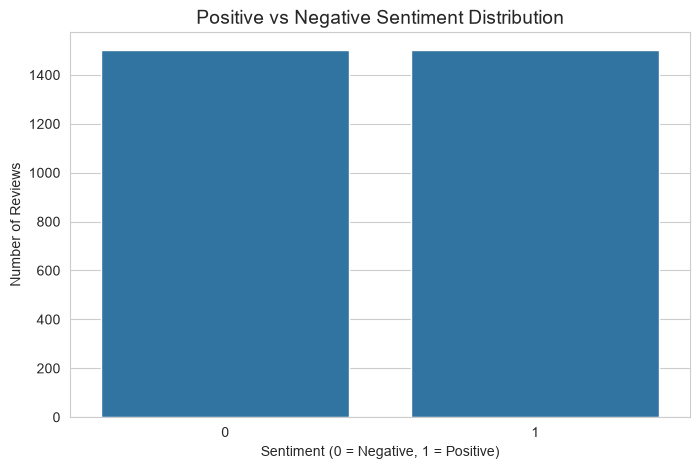

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='sentiment'
)

plt.title("Positive vs Negative Sentiment Distribution",
          fontsize=14)

plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

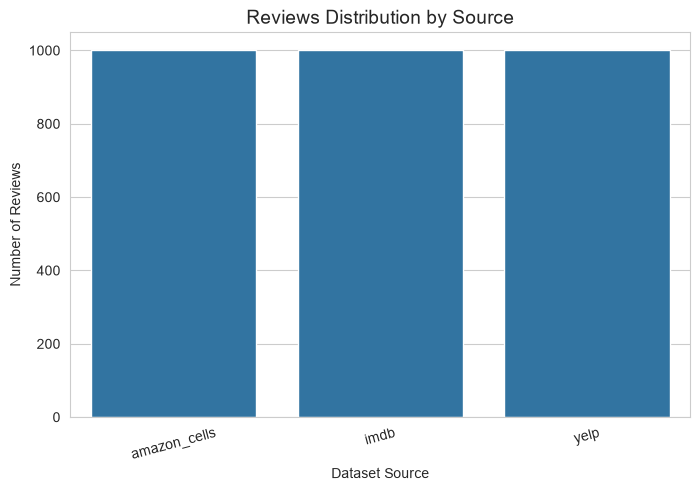

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='source'
)

plt.title("Reviews Distribution by Source", fontsize=14)
plt.xlabel("Dataset Source")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=15)
plt.show()

In [13]:
df['review_length'] = df['review'].apply(len)

print("Review Length Statistics:")
display(df['review_length'].describe())

Review Length Statistics:


count    3000.000000
mean       65.271333
std        44.160787
min         7.000000
25%        33.000000
50%        55.500000
75%        88.000000
max       479.000000
Name: review_length, dtype: float64

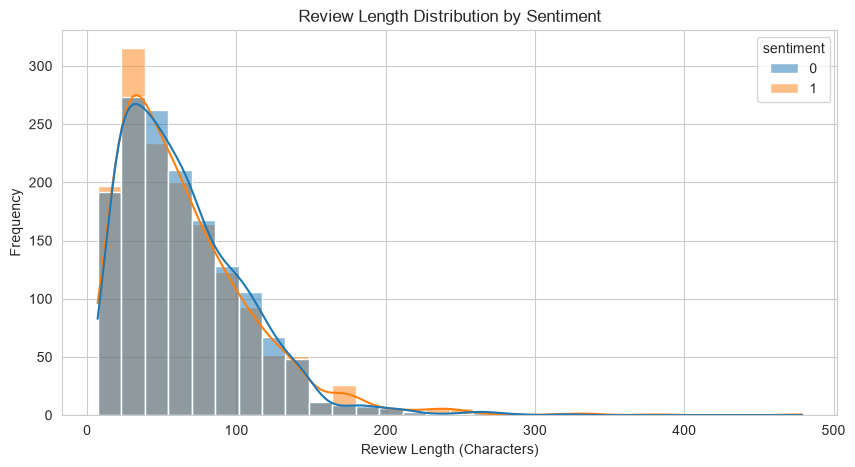

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='review_length',
    hue='sentiment',
    bins=30,
    kde=True
)

plt.title('Review Length Distribution by Sentiment')
plt.xlabel('Review Length (Characters)')
plt.ylabel('Frequency')

plt.show()

In [15]:
# Display sample reviews
for i in range(5):
    print(f"Review {i+1}: {df['review'].iloc[i]}")
    print("-" * 70)

Review 1: So there is no way for me to plug it in here in the US unless I go by a converter.
----------------------------------------------------------------------
Review 2: Good case, Excellent value.
----------------------------------------------------------------------
Review 3: Great for the jawbone.
----------------------------------------------------------------------
Review 4: Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
----------------------------------------------------------------------
Review 5: The mic is great.
----------------------------------------------------------------------


In [16]:
import re
import string

print("NLP libraries imported successfully!")

NLP libraries imported successfully!


In [17]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [19]:
import re
import string

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [20]:
df['cleaned_review'] = df['review'].apply(clean_text)

print("Text cleaning completed successfully!")

Text cleaning completed successfully!


In [21]:
comparison = df[['review', 'cleaned_review']].head(10)

display(comparison)

,review,cleaned_review
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


In [22]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df[['review', 'cleaned_review']].isnull().sum())

print("\nSample Cleaned Reviews:")
for review in df['cleaned_review'].head(5):
    print("-", review)

Dataset Shape: (3000, 5)

Missing Values:
review            0
cleaned_review    0
dtype: int64

Sample Cleaned Reviews:
- so there is no way for me to plug it in here in the us unless i go by a converter
- good case excellent value
- great for the jawbone
- tied to charger for conversations lasting more than minutesmajor problems
- the mic is great


In [23]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates().reset_index(drop=True)

print("After removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Before removing duplicates: (3000, 5)
After removing duplicates: (2983, 5)
Remaining duplicates: 0


In [24]:
print(df['sentiment'].value_counts())

print("\nSentiment Percentages:")
print(df['sentiment'].value_counts(normalize=True) * 100)

sentiment
0    1493
1    1490
Name: count, dtype: int64

Sentiment Percentages:
sentiment
0    50.050285
1    49.949715
Name: proportion, dtype: float64


In [25]:
from sklearn.model_selection import train_test_split

print("Train-test split library imported successfully!")

Train-test split library imported successfully!


In [26]:
X = df['cleaned_review']
y = df['sentiment']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2983,)
Target shape: (2983,)


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training data: (2386,)
Testing data: (597,)

Training labels:
sentiment
0    1194
1    1192
Name: count, dtype: int64

Testing labels:
sentiment
0    299
1    298
Name: count, dtype: int64


In [28]:
print("Training percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Training percentage: 79.99 %
Testing percentage: 20.01 %


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

TF-IDF imported successfully!


In [30]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

print("TF-IDF vectorizer created successfully!")

TF-IDF vectorizer created successfully!


In [31]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")

print("\nTraining TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

TF-IDF transformation completed!

Training TF-IDF Shape: (2386, 4407)
Testing TF-IDF Shape: (597, 4407)


In [32]:
feature_names = tfidf.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFirst 20 TF-IDF Features:")
print(feature_names[:20])

Total Features: 4407

First 20 TF-IDF Features:
['ability' 'ability to' 'able' 'able to' 'about' 'about half' 'about how'
 'about it' 'about minutes' 'about the' 'about this' 'about year' 'above'
 'above the' 'absolutely' 'absolutely no' 'abysmal' 'achievement' 'act'
 'acted']


In [34]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

print("All machine learning models imported successfully!")

All machine learning models imported successfully!


In [35]:
models = {
    "Naive Bayes": MultinomialNB(),
    
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    
    "Linear SVM": LinearSVC(
        random_state=42
    )
}

print("Models initialized successfully!")

Models initialized successfully!


In [36]:
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    
    model.fit(X_train_tfidf, y_train)
    
    trained_models[name] = model
    
    print(f"{name} training completed!\n")

print("All models trained successfully!")

Training Naive Bayes...
Naive Bayes training completed!

Training Logistic Regression...
Logistic Regression training completed!

Training Linear SVM...
Linear SVM training completed!

All models trained successfully!


In [37]:
predictions = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [39]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.8208,0.8237,0.8154,0.8196
1,Logistic Regression,0.7906,0.7893,0.7919,0.7906
2,Linear SVM,0.8275,0.8305,0.8221,0.8263


In [40]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(f"Classification Report: {name}")
    print("=" * 60)
    
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    ))

Classification Report: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.82      0.83      0.82       299
    Positive       0.82      0.82      0.82       298

    accuracy                           0.82       597
   macro avg       0.82      0.82      0.82       597
weighted avg       0.82      0.82      0.82       597

Classification Report: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.79      0.79      0.79       299
    Positive       0.79      0.79      0.79       298

    accuracy                           0.79       597
   macro avg       0.79      0.79      0.79       597
weighted avg       0.79      0.79      0.79       597

Classification Report: Linear SVM
              precision    recall  f1-score   support

    Negative       0.82      0.83      0.83       299
    Positive       0.83      0.82      0.83       298

    accuracy                           0.83       597
   macro avg    

<Figure size 1000x600 with 0 Axes>

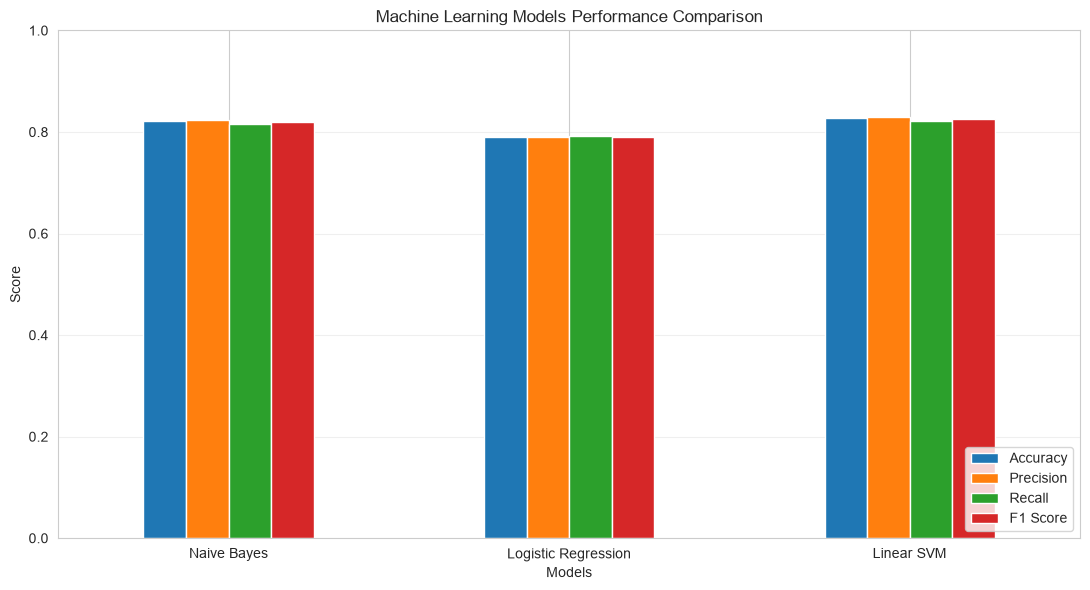

In [41]:
plt.figure(figsize=(10, 6))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Machine Learning Models Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Models')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(), 'Model'
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", round(
    results_df['F1 Score'].max(), 4
))

Best Model: Linear SVM
Best F1 Score: 0.8263


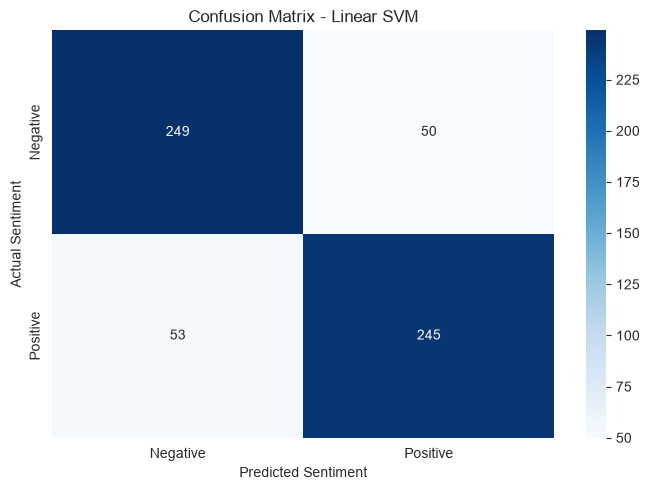

In [43]:
from sklearn.metrics import confusion_matrix

best_predictions = predictions[best_model_name]

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.tight_layout()
plt.show()

In [44]:
import joblib
import os

print("Joblib imported successfully!")

Joblib imported successfully!


In [45]:
os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [46]:
joblib.dump(best_model, "models/sentiment_model.pkl")

joblib.dump(tfidf, "models/tfidf_vectorizer.pkl")

print("Best model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Best model saved successfully!
TF-IDF vectorizer saved successfully!


In [47]:
print("Saved Model Files:")

print(os.listdir("models"))

Saved Model Files:
['sentiment_model.pkl', 'tfidf_vectorizer.pkl']


In [48]:
loaded_model = joblib.load("models/sentiment_model.pkl")

loaded_tfidf = joblib.load("models/tfidf_vectorizer.pkl")

print("Model and vectorizer loaded successfully!")

Model and vectorizer loaded successfully!


In [49]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)

    review_vector = loaded_tfidf.transform([cleaned_review])

    prediction = loaded_model.predict(review_vector)[0]

    if prediction == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"

In [50]:
test_reviews = [
    "This product is amazing and works perfectly!",
    "I hate this product. It is terrible.",
    "The quality is excellent and I am very happy.",
    "Worst experience ever. Completely disappointed.",
    "The product is okay, nothing special."
]

for review in test_reviews:
    result = predict_sentiment(review)

    print("Review:", review)
    print("Predicted Sentiment:", result)
    print("-" * 60)

Review: This product is amazing and works perfectly!
Predicted Sentiment: Positive 😊
------------------------------------------------------------
Review: I hate this product. It is terrible.
Predicted Sentiment: Negative 😞
------------------------------------------------------------
Review: The quality is excellent and I am very happy.
Predicted Sentiment: Positive 😊
------------------------------------------------------------
Review: Worst experience ever. Completely disappointed.
Predicted Sentiment: Negative 😞
------------------------------------------------------------
Review: The product is okay, nothing special.
Predicted Sentiment: Negative 😞
------------------------------------------------------------
